# Topics for Test 2

 - Date: Friday Nov 13
 - Location: MSB 3011

In [4]:
import numpy as np
import scipy
import time
import matplotlib.pyplot as plt
from PIL import Image

In [8]:
A = np.random.randint(low=-5, high=5, size=(5, 5))

## Solving system of equations

- Implement a function to solve a system using forward or backward substitution (HW #5)
- Run the test cases (The instruction will be given)
- Compute the error while solving the system of equations using these method. Compare your function with `np.linalg.solve(A, b)`.

In [ ]:
def forward_substitution(l, b):
    # Solves Lx = b where L is a lower triangular matrix
    n = len(b)
    x = np.empty(shape=n, dtype=float)

    for i in range(n):
        x[i] = (b[i] - np.dot(x[:i], l[i, :i])) / l[i, i]
    return x

In [ ]:
def backward_substitution(u, b):
    # Solves Ux = b where U is an upper triangular matrix
    n = len(b)
    x = np.empty(shape=n, dtype=float)

    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - np.dot(x[i+1:], u[i, i+1:])) / u[i, i]
    return x

## LU Decomposition - Complexity

- Use `scipy.linalg.lu` to decompose matrices, record the running time and plot the graph. (HW #5)
- Check the theoretical result $O(n^3)$ vs the experimental result from your work.

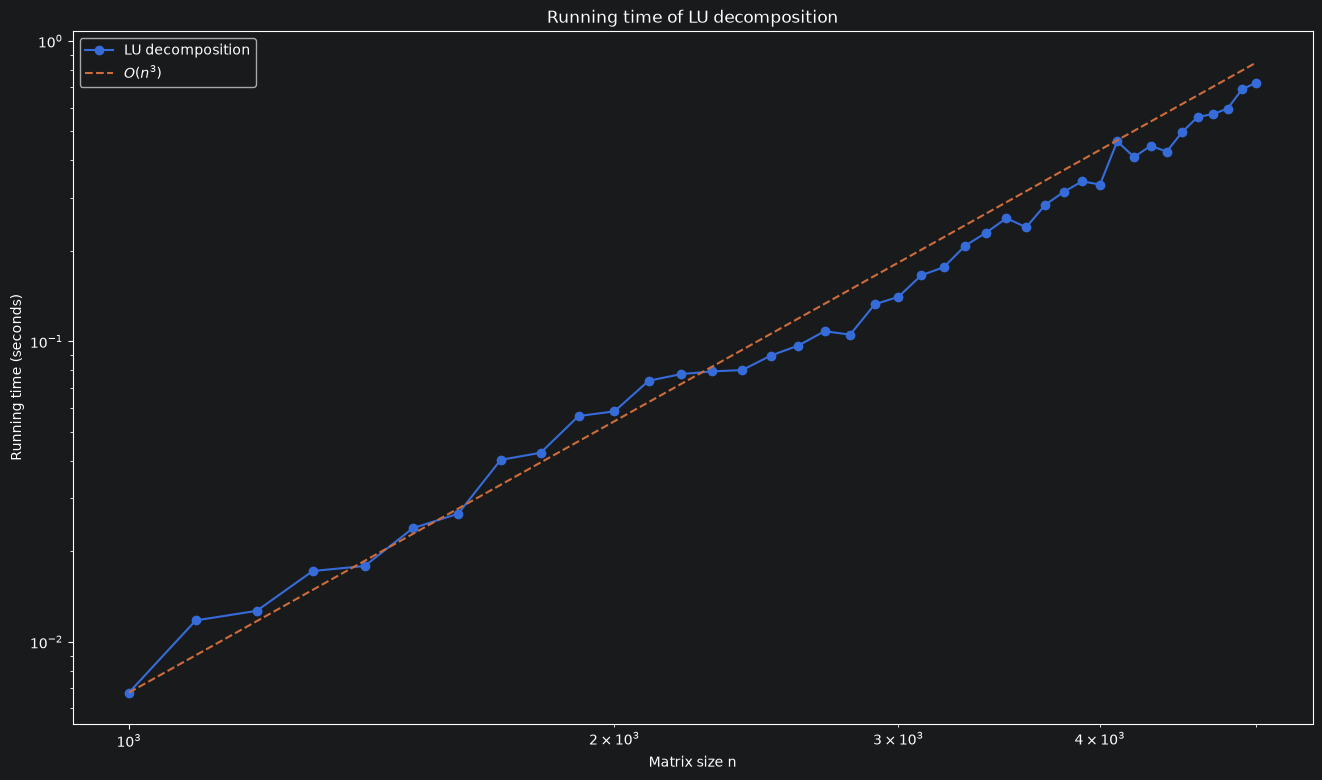

In [6]:
sizes = np.arange(1_000, 5_001, 100)
times = []

scipy.linalg.lu(np.random.rand(1000, 1000)) # Pre-initialize BLAS
for n in sizes:
    A = np.random.randint(1, 10, size=(n, n))

    start = time.time()
    scipy.linalg.lu(A)
    end = time.time()

    times.append(end - start)

fig, ax = plt.subplots(figsize=(16, 9))

ax.loglog(sizes, times, "o-", label="LU decomposition")
ax.loglog(sizes, times[0] * (sizes / sizes[0])**3, "--", label=r"$O(n^3)$")

ax.set_title("Running time hoof LU decomposition")
ax.set_xlabel("Matrix size n")
ax.set_ylabel("Running time (seconds)")
ax.legend()

plt.show()

In [7]:
slope, intercept = np.polyfit(np.log(sizes), np.log(times), 1)
print(f"Actual slope = {slope:.2f}")
print("Theoretical slope = 3")

Actual slope = 2.75
Theoretical slope = 3


## power method

- Find the largest eigenvalue of a matrix (This is the dominant eigenvalue)
- Implement the power method for max_iter=500
- Test cases: (Given instruction on the test)
- Convergent analysis: Theorem said: $error_k = O\left(\left| \frac{\lambda_2}{\lambda_1} \right|^k\right)$.
- Check HW #6

In [ ]:
def power_method(A, x0, tol=1e-10, max_iter=500):
    x = x0 / np.linalg.norm(x0)
    errors = []
    converged = False
    lamb = None
    for i in range(max_iter):
        y = A @ x
        lamb = x @ y
        err = np.linalg.norm(y - lamb * x)
        errors.append(err)
        if err < tol:
            converged = True
            print(f"Algorithm converged at step {i+1}")
            break

        y_norm = np.linalg.norm(y)
        x = y / y_norm

    return lamb, x, converged, errors

In [9]:
vals = np.sort(np.abs(np.linalg.eigvals(A)))[::-1]
r = vals[1] / vals[0]

k = np.arange(len(errors))
slope, _ = np.polyfit(k, np.log(errors), 1)
print(f"Measured slope = {slope:.3f}, theoretical log(r) = {np.log(r):.3f}")

plt.semilogy(k, errors, "o-", label="error")
plt.semilogy(k, errors[0] * r**k, "--", label=r"$|\lambda_2/\lambda_1|^k$")
plt.xlabel("k")
plt.ylabel("error")
plt.legend()
plt.show()

## Application of SVD to image processing


- Load an image and compute its svd using `np.linalg.svd`.
- Given the percentage of the covariance (keep 90% of the quality of the image), find the number of $k$.
- Use this $k$ to reconstruct the image and plot it with `ax.imshow(img, cmap="gray")`.
- Plot a series of images with different $k$ (20 values of $k$) (HW #7)

In [ ]:
img = Image.open("img.jpg").convert("L")
img_arr = np.array(img)

U, S, VT = np.linalg.svd(img_arr, full_matrices=False)

total_variance = np.sum(S**2)
accum_var = np.cumsum(S**2) / total_variance

k = np.argmax(accum_var >= 0.9) + 1

img_k = U[:, :k] @ np.diag(S[:k]) @ VT[:k, :]

k_vals = np.arange(5, 101, 5)

fig, axs = plt.subplots(nrows=4, ncols=5, figsize=(16, 9))

axs[0, 0].imshow(img_arr, cmap="gray")
axs[0, 0].set_title("original")
axs[0, 0].set_axis_off()

for i, k in enumerate(k_vals, start=1):
    row_idx = i // 5
    col_idx = i % 5
    U_k = U[:, :k]
    S_k = np.diag(S[:k])
    VT_k = VT[:k, :]
    img_k = np.real(U_k @ (S_k @ VT_k))
    axs[row_idx, col_idx].imshow(img_k, cmap="gray")
    axs[row_idx, col_idx].set_title(f"k = {k}")m
    axs[row_idx, col_idx].set_axis_off()

plt.tight_layout()
plt.show()